In [1]:

import torch
import torch.nn.functional as F
import numpy as np
from abc import ABC, abstractmethod

from rank_bm25 import BM25Okapi
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

from load_experiment_data import (
    train_dataset_name,
    test_dataset_name,
    train_dataset_split,
    test_dataset_split,
    load_data_and_estimators,
)

from influence_estimation.util import tokenize_dataset

from huggingface_hub import hf_hub_download
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import PeftModel
from sentence_transformers import SentenceTransformer

import json
import os

In [2]:
torch.manual_seed(42)
np.random.seed(42)


train_dataset, test_dataset, estimators = load_data_and_estimators()


influence_estimate_path: ./results/influence/LESSEstimator/8192-True/Llama-3.2-1B_tulu-3-sft-olmo-2-mixture-0225_lr0.0001_seed42/tulu-3-sft-olmo-2-mixture-0225-sample_train/tulu-3-sft-olmo-2-mixture-0225-sample_test/estimate.parquet
dirname: ./results/influence/LESSEstimator/8192-True/Llama-3.2-1B_tulu-3-sft-olmo-2-mixture-0225_lr0.0001_seed42/tulu-3-sft-olmo-2-mixture-0225-sample_train/tulu-3-sft-olmo-2-mixture-0225-sample_test
exists: True


In [ ]:
from representations import GradientRepresentation, FullModelRepresentation, SBERTRepresentation, BM25Representation, TFIDFRepresentation, JaccardRepresentation, OverlapRepresentation, BaseRepresentation, NormalizedAttentionMapRepresentation,RepSimRepresentation

SyntaxError: invalid syntax (64247105.py, line 1)

In [ ]:
import numpy as np
from utils import load_lora_model
from influence_estimation.util import tokenize_dataset
from sentence_transformers import SentenceTransformer
from tqdm import tqdm


dataset_length = len(train_dataset)
np.random.seed(42)
random_indices = np.random.choice(dataset_length, size=50, replace=False)


model_configs = {
    # "olmo-tarot": "barissglc/tinyllama-tarot-v1",
    "olmo2": "loris3/OLMo-2-0425-1B_tulu-3-sft-olmo-2-mixture-0225_lr0.0001_seed42",
    # "qwen": "loris3/Qwen2.5-0.5B_tulu-3-sft-olmo-2-mixture-0225_lr0.0001_seed42",
     "llama": "loris3/Llama-3.2-1B_tulu-3-sft-olmo-2-mixture-0225_lr0.0001_seed42",
     
}


features = {}


for est in estimators:
    rep = GradientRepresentation(est, train_dataset_name, train_dataset_split, random_indices)
    features[rep.name] = rep.compute()

st_model = SentenceTransformer("all-MiniLM-L6-v2")

# needs a tokenizer that supports apply_chat_template
_,tokenizer_sample_model = load_lora_model(model_configs[list(model_configs.keys())[0]])
tokenized_sample_dataset = tokenize_dataset(
    train_dataset.select(random_indices),
    tokenizer_sample_model,
    max_length=512,
    num_proc=10,
    re_index=False,
)
decoded_texts_sample = [tokenizer_sample_model.decode(m["input_ids"]) for m in tokenized_sample_dataset]
tokenized_docs = tokenized_sample_dataset["input_ids"]

print("sbert")
rep = SBERTRepresentation(st_model, decoded_texts_sample)
features[rep.name] = rep.compute()
del st_model

for rep_class in [BM25Representation, TFIDFRepresentation, JaccardRepresentation, OverlapRepresentation]:
    rep = rep_class(tokenized_docs)
    features[rep.name] = rep.compute()


del tokenizer_sample_model


for name, path in model_configs.items():
    print(f"Processing model: {name}")
    model, tokenizer = load_lora_model(path)

    tokenized_dataset = tokenize_dataset(
        train_dataset.select(random_indices),
        tokenizer,
        max_length=512,
        num_proc=10,
        re_index=False,
    )

    rep = NormalizedAttentionMapRepresentation(model=model, tokenized_dataset=tokenized_dataset, name=f"rep_sim_{name}")
    features[rep.name] = rep.compute()


    rep = FullModelRepresentation(model=model, tokenized_dataset=tokenized_dataset, name=f"full_model_{name}")
    features[rep.name] = rep.compute()
    
    rep = RepSimRepresentation(model=model, tokenized_dataset=tokenized_dataset, name=f"full_model_{name}")
    features[rep.name] = rep.compute()

    del model, tokenizer, tokenized_dataset

print("All features computed!")

Computing LESSEstimator embeddings:   0%|          | 0/50 [00:00<?, ?it/s]

Computing LESSEstimator embeddings: 100%|██████████| 50/50 [00:00<00:00, 92.94it/s] 
[INFO] Use pytorch device_name: cuda:0
[INFO] Load pretrained SentenceTransformer: all-MiniLM-L6-v2


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

... (13 outputs left out)

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/623 [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/4.98G [00:00<?, ?B/s]

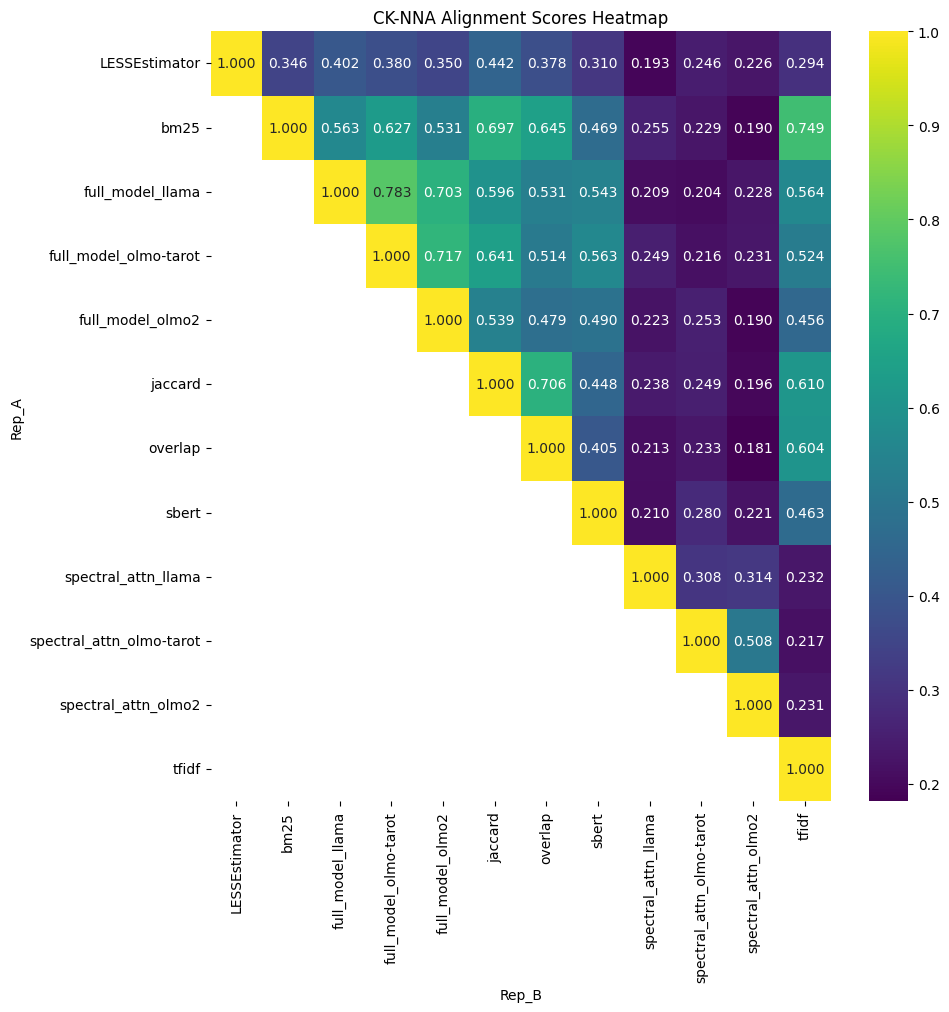

In [ ]:
import torch
import torch.nn.functional as F
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from metrics import AlignmentMetrics
from itertools import combinations

# Dictionary of feature sets

# Normalize all feature sets on GPU
features = {k: F.normalize(v, dim=-1) for k, v in features.items()}

# Compute pairwise CK-NNA scores
results = []
for (name1, feat1), (name2, feat2) in combinations(features.items(), 2):
    
    score = AlignmentMetrics.cknna(feat1.cpu(), feat2.cpu(), topk=10)
    results.append((name1, name2, score))
    results.append((name2, name1, score))  # fill symmetric entry

# Add diagonal entries (self-similarity)
for name, feat in features.items():
    results.append((name, name, 1.0))  # CK-NNA score with self = 1.0

# Convert to DataFrame
df_scores = pd.DataFrame(results, columns=["Rep_A", "Rep_B", "CKNNA_score"])

heatmap_data = df_scores.pivot(index="Rep_A", columns="Rep_B", values="CKNNA_score")

mask = np.tril(np.ones_like(heatmap_data, dtype=bool), k=-1)  # k=-1 keeps diagonal

plt.figure(figsize=(10, 10))
sns.heatmap(heatmap_data, annot=True, fmt=".3f", cmap="viridis", mask=mask)
plt.title("CK-NNA Alignment Scores Heatmap")
plt.show()

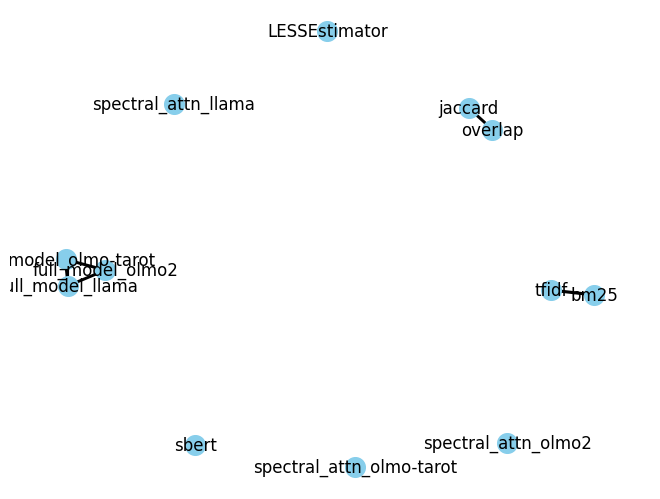

In [ ]:
import networkx as nx

G = nx.Graph()


for name in heatmap_data.index:
    G.add_node(name)


threshold = 0.7
for i, name1 in enumerate(heatmap_data.index):
    for j, name2 in enumerate(heatmap_data.columns):
        if i < j and heatmap_data.loc[name1, name2] > threshold:
            G.add_edge(name1, name2, weight=heatmap_data.loc[name1, name2])

# Draw graph
pos = nx.spring_layout(G, seed=42)
edges = G.edges()
weights = [G[u][v]['weight']*3 for u,v in edges]  # scale weights
nx.draw(G, pos, with_labels=True, width=weights, node_size=200, node_color="skyblue")

plt.show()